# 第095讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: [build path redacted]


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "gradient_check": {
    "finite_difference_max_error": 5.607736497381666e-13,
    "autograd_max_error": 9.540979117872439e-18
  },
  "runs": [
    {
      "seed": 0,
      "model": "linear",
      "accuracy": 0.5766666531562805,
      "class0_accuracy": 0.5400000214576721,
      "class1_accuracy": 0.6133333444595337,
      "parameters": 202,
      "updates": 100,
      "train_seconds": 1.0900568440001734,
      "error_indices": [
        2,
        4,
        5,
        6,
        9,
        16,
        17,
        18,
        19,
        20,
        21,
        25,
        28,
        39,
        40,
        45,
        51,
        52,
        55,
        56,
        58,
        61,
        62,
        63,
        65,
        66,
        77,
        78,
        80,
        82,
        85,
        86,
        89,
        94,
        96,
        97,
        98,
        100,
        102,
        104,
        107,
        109,
        110,
        112,
        114,
        115,
      

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_balanced_splits (test_experiment.TestMechanism.test_balanced_splits) ... ok
test_manual_gradient (test_experiment.TestMechanism.test_manual_gradient) ... ok
test_one_sample_gradient (test_experiment.TestMechanism.test_one_sample_gradient) ... ok
test_prediction_shape (test_experiment.TestMechanism.test_prediction_shape) ... ok
test_zero_input_gradient (test_experiment.TestMechanism.test_zero_input_gradient) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.028s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['gradient_check', 'runs', 'summary', 'seconds', 'environment']


01_comparison.png
02_training.png
03_mechanism.png


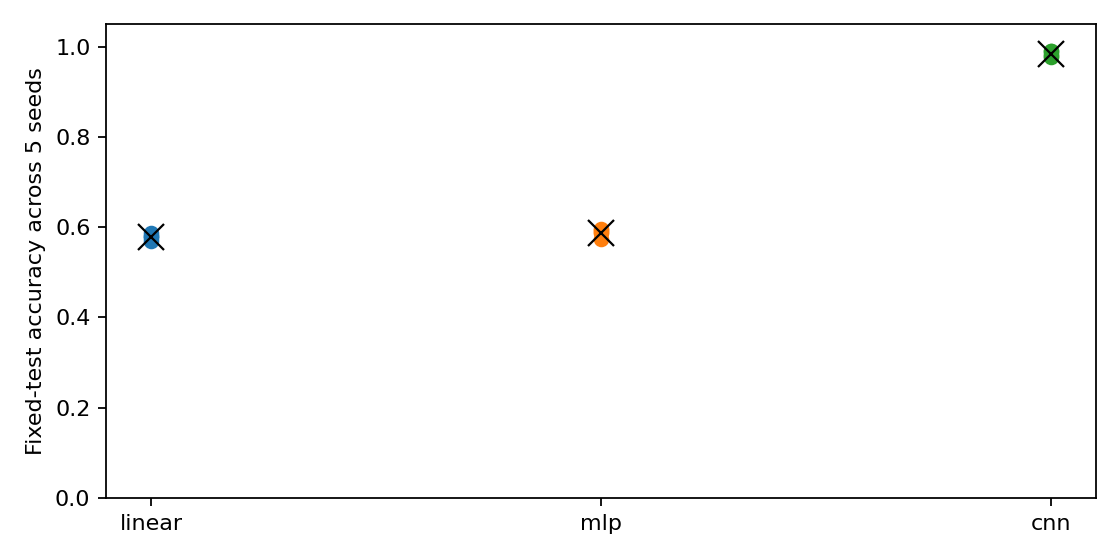

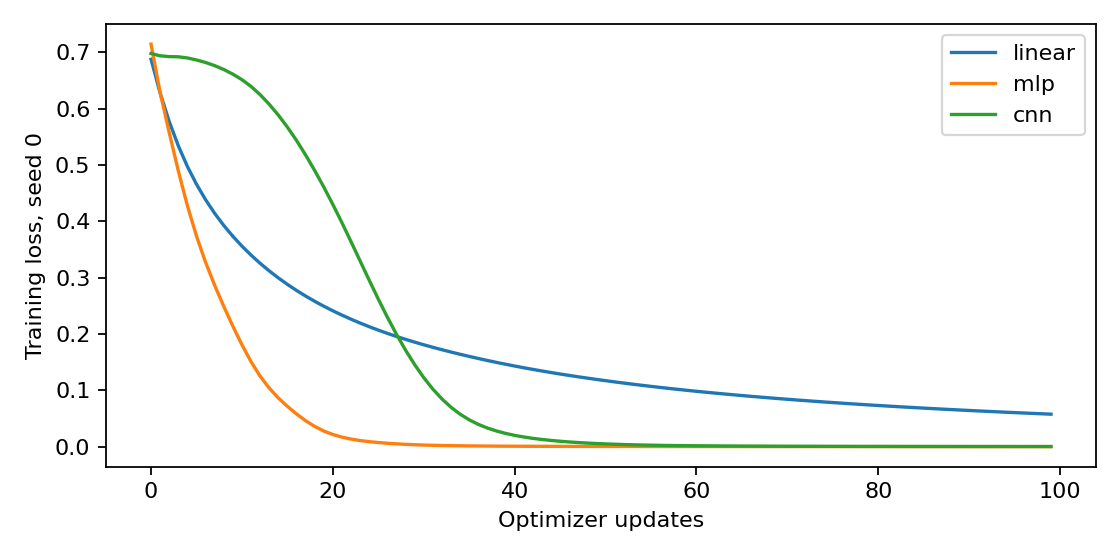

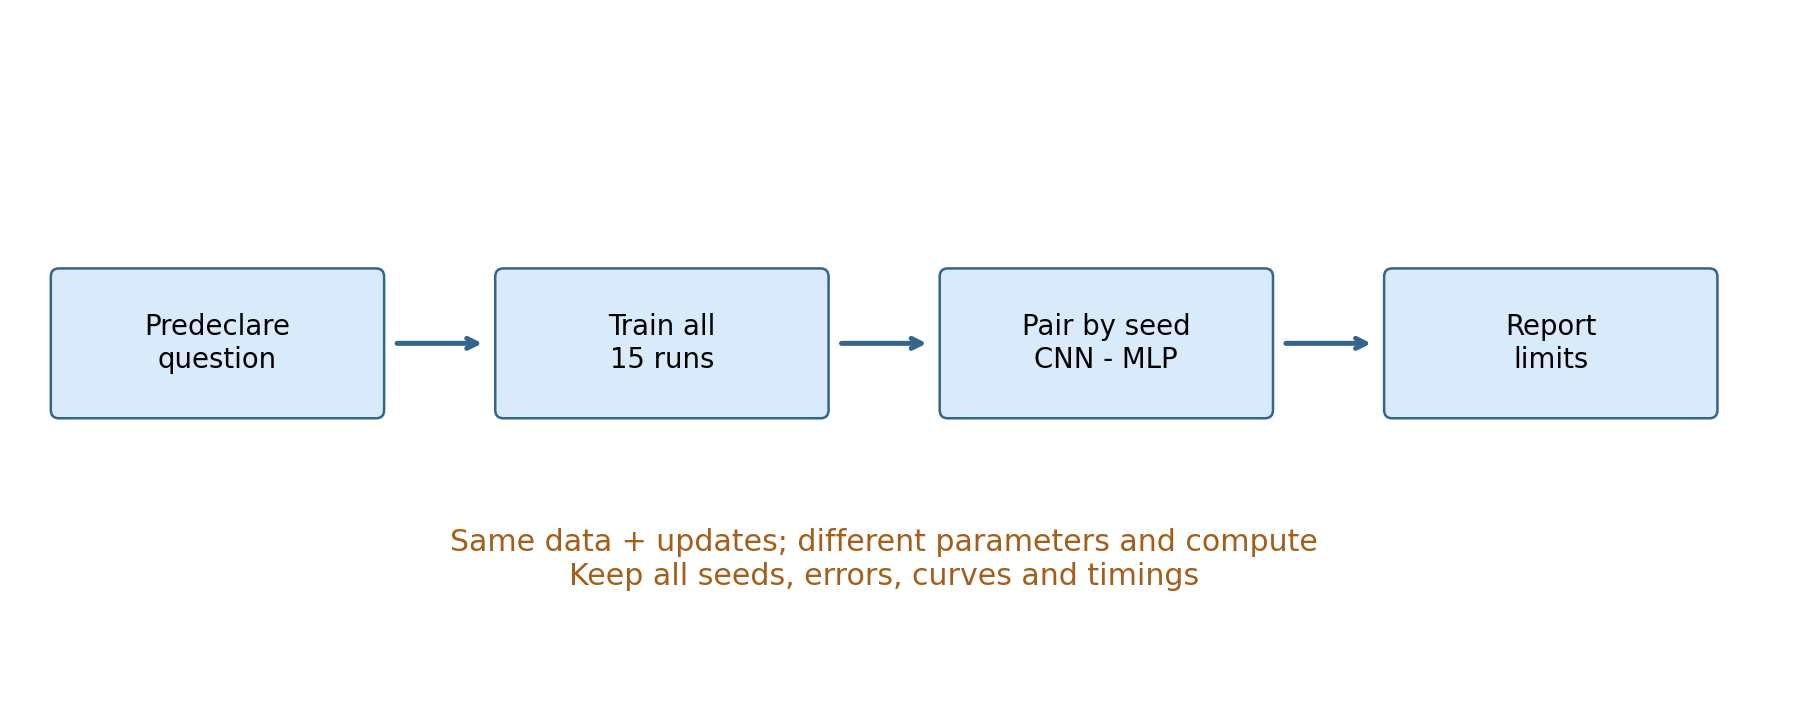

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。